In [1]:
# #step 1 - Import required libraries

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

np.random.seed(42)

print("Libraries imported successfully!")
print("NumPy version:", np.__version__)

Libraries imported successfully!
NumPy version: 2.1.3


In [2]:
# #step 2 - Create binary classification datasets (AND and XOR)

# Input combinations
X = np.array([
    [0, 0],
    [0, 1],
    [1, 0],
    [1, 1]
])

# AND operation
y_and = np.array([0, 0, 0, 1])

# XOR operation
y_xor = np.array([0, 1, 1, 0])

print("Input data:")
print(X)

print("\nAND outputs:")
print(y_and)

print("\nXOR outputs:")
print(y_xor)

Input data:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]

AND outputs:
[0 0 0 1]

XOR outputs:
[0 1 1 0]


In [3]:
# #step 3 - Implement a single-layer perceptron

class Perceptron:

    def __init__(self, input_size, learning_rate=0.1, epochs=100):
        self.weights = np.zeros(input_size)
        self.bias = 0.0
        self.learning_rate = learning_rate
        self.epochs = epochs

    # Step activation function
    def activation(self, z):
        return (z >= 0).astype(int)

    # Prediction
    def predict(self, X):
        z = np.dot(X, self.weights) + self.bias
        return self.activation(z)

    # Training
    def fit(self, X, y):

        for epoch in range(self.epochs):

            for xi, target in zip(X, y):

                z = np.dot(xi, self.weights) + self.bias
                prediction = self.activation(np.array([z]))[0]

                error = target - prediction

                self.weights += self.learning_rate * error * xi
                self.bias += self.learning_rate * error

        return self


# Train perceptron on AND dataset
perceptron_and = Perceptron(input_size=2)

perceptron_and.fit(X, y_and)

predictions_and = perceptron_and.predict(X)

print("AND Classification")
print("------------------")
print("Actual outputs:    ", y_and)
print("Predicted outputs: ", predictions_and)

print("Accuracy:",
      np.mean(predictions_and == y_and) * 100, "%")

AND Classification
------------------
Actual outputs:     [0 0 0 1]
Predicted outputs:  [0 0 0 1]
Accuracy: 100.0 %


In [4]:
# #step 4 - Demonstrate why a single-layer perceptron fails on XOR

perceptron_xor = Perceptron(
    input_size=2,
    learning_rate=0.1,
    epochs=100
)

perceptron_xor.fit(X, y_xor)

predictions_xor = perceptron_xor.predict(X)

print("XOR Classification")
print("------------------")
print("Actual outputs:    ", y_xor)
print("Predicted outputs: ", predictions_xor)

accuracy = np.mean(predictions_xor == y_xor) * 100

print("Accuracy:", accuracy, "%")

XOR Classification
------------------
Actual outputs:     [0 1 1 0]
Predicted outputs:  [1 1 0 0]
Accuracy: 50.0 %


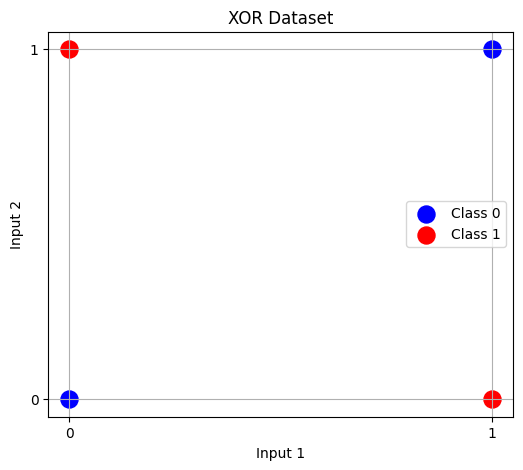

In [5]:
# #step 4 - Visualize XOR data and its classes

plt.figure(figsize=(6, 5))

for label, color, name in [
    (0, "blue", "Class 0"),
    (1, "red", "Class 1")
]:

    mask = y_xor == label

    plt.scatter(
        X[mask, 0],
        X[mask, 1],
        color=color,
        s=150,
        label=name
    )

plt.xlabel("Input 1")
plt.ylabel("Input 2")
plt.title("XOR Dataset")
plt.xticks([0, 1])
plt.yticks([0, 1])
plt.grid(True)
plt.legend()
plt.show()

In [6]:
# #step 5 - Implement MLP forward propagation and activation functions

def sigmoid(x):
    x = np.clip(x, -500, 500)
    return 1 / (1 + np.exp(-x))


def sigmoid_derivative(x):
    s = sigmoid(x)
    return s * (1 - s)


def tanh_activation(x):
    return np.tanh(x)


def tanh_derivative(x):
    return 1 - np.tanh(x) ** 2


def relu_activation(x):
    return np.maximum(0, x)


def relu_derivative(x):
    return (x > 0).astype(float)


class MLP:

    def __init__(self, input_size, hidden_size, output_size,
                 hidden_activation="tanh"):

        self.hidden_activation = hidden_activation

        # Initialize weights
        self.W1 = np.random.randn(input_size, hidden_size) * 0.5
        self.b1 = np.zeros((1, hidden_size))

        self.W2 = np.random.randn(hidden_size, output_size) * 0.5
        self.b2 = np.zeros((1, output_size))

    def hidden_forward(self, z):

        if self.hidden_activation == "tanh":
            return tanh_activation(z)

        elif self.hidden_activation == "relu":
            return relu_activation(z)

        else:
            raise ValueError("Unsupported hidden activation")

    def forward(self, X):

        # Input to hidden layer
        self.z1 = np.dot(X, self.W1) + self.b1
        self.a1 = self.hidden_forward(self.z1)

        # Hidden layer to output layer
        self.z2 = np.dot(self.a1, self.W2) + self.b2
        self.a2 = sigmoid(self.z2)

        return self.a2


print("MLP forward propagation implemented successfully!")

MLP forward propagation implemented successfully!


In [7]:
# #step 6 - Implement backpropagation and train MLP on XOR

class MLP(MLP):

    def backward(self, X, y, learning_rate=0.1):

        m = X.shape[0]

        # Output layer gradient
        dz2 = (self.a2 - y) / m

        dW2 = np.dot(self.a1.T, dz2)
        db2 = np.sum(dz2, axis=0, keepdims=True)

        # Hidden layer gradient
        if self.hidden_activation == "tanh":
            dz1 = np.dot(dz2, self.W2.T) * tanh_derivative(self.z1)

        else:
            dz1 = np.dot(dz2, self.W2.T) * relu_derivative(self.z1)

        dW1 = np.dot(X.T, dz1)
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # Update weights and biases
        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2

        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1


def binary_cross_entropy(y, predictions):

    predictions = np.clip(predictions, 1e-12, 1 - 1e-12)

    return -np.mean(
        y * np.log(predictions) +
        (1 - y) * np.log(1 - predictions)
    )


# Prepare XOR data
X_xor = X.astype(float)
y_xor_reshaped = y_xor.reshape(-1, 1).astype(float)

# Create MLP
np.random.seed(42)

mlp = MLP(
    input_size=2,
    hidden_size=4,
    output_size=1,
    hidden_activation="tanh"
)

# Training
epochs = 10000
learning_rate = 0.1

loss_history = []

for epoch in range(epochs):

    predictions = mlp.forward(X_xor)

    loss = binary_cross_entropy(y_xor_reshaped, predictions)

    mlp.backward(X_xor, y_xor_reshaped, learning_rate)

    loss_history.append(loss)


# Final predictions
final_predictions = mlp.forward(X_xor)
binary_predictions = (final_predictions >= 0.5).astype(int)

print("Actual XOR outputs:")
print(y_xor)

print("\nMLP predictions:")
print(binary_predictions.flatten())

print("\nPredicted probabilities:")
print(final_predictions.flatten())

print("\nFinal accuracy:",
      np.mean(binary_predictions.flatten() == y_xor) * 100, "%")

print("Final loss:", loss_history[-1])

Actual XOR outputs:
[0 1 1 0]

MLP predictions:
[0 1 1 0]

Predicted probabilities:
[3.10945782e-04 9.97044301e-01 9.96925170e-01 4.45338033e-03]

Final accuracy: 100.0 %
Final loss: 0.002703799897969323


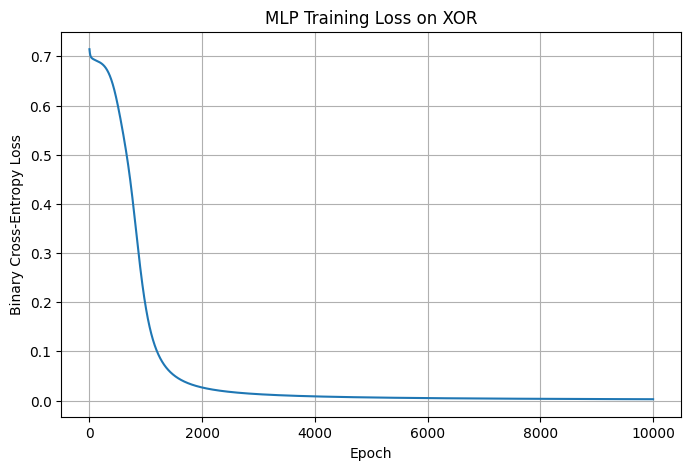

In [8]:
# #step 6 - Visualize MLP training loss on XOR

plt.figure(figsize=(8, 5))

plt.plot(loss_history)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy Loss")
plt.title("MLP Training Loss on XOR")
plt.grid(True)

plt.show()

In [9]:
# #step 7 - Verify analytical gradients using numerical gradient checking

def calculate_gradients(model, X, y):

    m = X.shape[0]

    # Forward propagation
    model.forward(X)

    # Output gradients
    dz2 = (model.a2 - y) / m

    dW2 = np.dot(model.a1.T, dz2)
    db2 = np.sum(dz2, axis=0, keepdims=True)

    # Hidden gradients
    if model.hidden_activation == "tanh":
        dz1 = np.dot(dz2, model.W2.T) * tanh_derivative(model.z1)
    else:
        dz1 = np.dot(dz2, model.W2.T) * relu_derivative(model.z1)

    dW1 = np.dot(X.T, dz1)
    db1 = np.sum(dz1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2


def numerical_gradient(model, X, y, parameter, index, epsilon=1e-5):

    original_value = parameter[index]

    parameter[index] = original_value + epsilon
    loss_plus = binary_cross_entropy(y, model.forward(X))

    parameter[index] = original_value - epsilon
    loss_minus = binary_cross_entropy(y, model.forward(X))

    parameter[index] = original_value

    return (loss_plus - loss_minus) / (2 * epsilon)


# Small network for gradient checking
np.random.seed(10)

test_model = MLP(2, 3, 1, hidden_activation="tanh")

X_test = np.array([
    [0.2, 0.4],
    [0.5, 0.7]
])

y_test = np.array([
    [0.0],
    [1.0]
])

# Analytical gradients
dW1, db1, dW2, db2 = calculate_gradients(
    test_model, X_test, y_test
)

# Numerical gradients
num_W1 = numerical_gradient(
    test_model, X_test, y_test, test_model.W1, (0, 0)
)

num_W2 = numerical_gradient(
    test_model, X_test, y_test, test_model.W2, (0, 0)
)

num_b1 = numerical_gradient(
    test_model, X_test, y_test, test_model.b1, (0, 0)
)

num_b2 = numerical_gradient(
    test_model, X_test, y_test, test_model.b2, (0, 0)
)

# Compare gradients
comparison = pd.DataFrame({
    "Parameter": ["W1[0,0]", "W2[0,0]", "b1[0,0]", "b2[0,0]"],
    "Analytical Gradient": [
        dW1[0, 0], dW2[0, 0], db1[0, 0], db2[0, 0]
    ],
    "Numerical Gradient": [
        num_W1, num_W2, num_b1, num_b2
    ]
})

comparison["Absolute Difference"] = np.abs(
    comparison["Analytical Gradient"] -
    comparison["Numerical Gradient"]
)

print(comparison.to_string(index=False))

print("\nMaximum gradient difference:",
      comparison["Absolute Difference"].max())

Parameter  Analytical Gradient  Numerical Gradient  Absolute Difference
  W1[0,0]            -0.007840           -0.007840         1.181314e-11
  W2[0,0]            -0.044046           -0.044046         4.331674e-13
  b1[0,0]             0.004160            0.004160         2.053181e-12
  b2[0,0]             0.011091            0.011091         3.400504e-12

Maximum gradient difference: 1.1813142478112049e-11


In [10]:
# #step 8 - Implement and compare weight initialization methods

def initialize_weights(input_size, hidden_size, output_size, method):

    if method == "zero":

        W1 = np.zeros((input_size, hidden_size))
        W2 = np.zeros((hidden_size, output_size))

    elif method == "random":

        W1 = np.random.randn(input_size, hidden_size) * 0.1
        W2 = np.random.randn(hidden_size, output_size) * 0.1

    elif method == "xavier":

        W1 = np.random.randn(input_size, hidden_size) * np.sqrt(
            1 / input_size
        )

        W2 = np.random.randn(hidden_size, output_size) * np.sqrt(
            1 / hidden_size
        )

    elif method == "he":

        W1 = np.random.randn(input_size, hidden_size) * np.sqrt(
            2 / input_size
        )

        W2 = np.random.randn(hidden_size, output_size) * np.sqrt(
            2 / hidden_size
        )

    else:
        raise ValueError("Unknown initialization method")

    return W1, W2


methods = ["zero", "random", "xavier", "he"]

initialization_results = []

for method in methods:

    np.random.seed(42)

    W1, W2 = initialize_weights(2, 4, 1, method)

    initialization_results.append({
        "Method": method,
        "W1 Mean": np.mean(W1),
        "W1 Standard Deviation": np.std(W1),
        "W2 Mean": np.mean(W2),
        "W2 Standard Deviation": np.std(W2)
    })


initialization_df = pd.DataFrame(initialization_results)

print(initialization_df.round(4).to_string(index=False))

Method  W1 Mean  W1 Standard Deviation  W2 Mean  W2 Standard Deviation
  zero   0.0000                 0.0000   0.0000                 0.0000
random   0.0551                 0.0686  -0.0214                 0.0437
xavier   0.3896                 0.4854  -0.1070                 0.2184
    he   0.5509                 0.6864  -0.1513                 0.3089


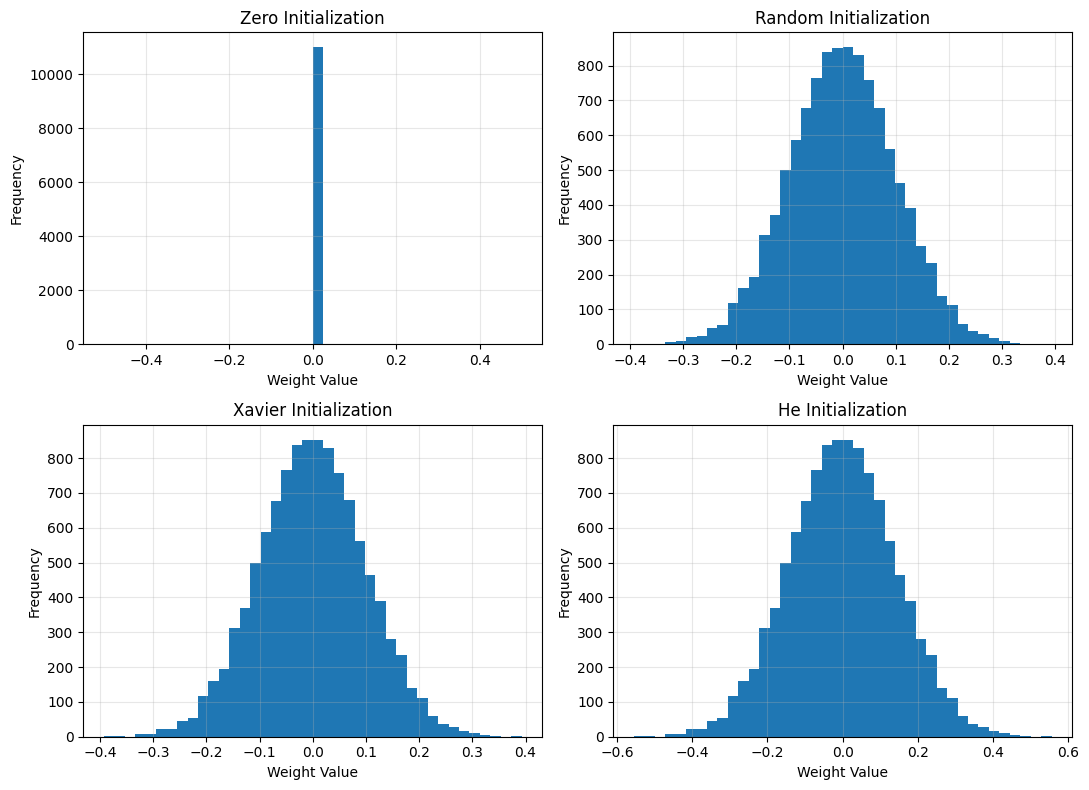

In [11]:
# #step 8 - Visualize weight distributions for different initialization methods

fig, axes = plt.subplots(2, 2, figsize=(11, 8))

for ax, method in zip(axes.flatten(), methods):

    np.random.seed(42)

    W1, W2 = initialize_weights(100, 100, 10, method)

    all_weights = np.concatenate([
        W1.flatten(),
        W2.flatten()
    ])

    ax.hist(all_weights, bins=40)

    ax.set_title(method.capitalize() + " Initialization")
    ax.set_xlabel("Weight Value")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

observations
- Zero initialization gives identical weights, preventing hidden neurons from learning different features due to symmetry.
- Random initialization breaks symmetry and allows neurons to learn different patterns.
- Xavier initialization is designed to maintain signal variance across layers, particularly with Tanh and Sigmoid activations.
- He initialization uses a larger variance and is commonly suitable for ReLU-based networks.
Note that this experiment compares initial weight distributions. We will use these methods in the Fashion-MNIST experiment to compare their training performance

In [12]:
# #step 9 - Load Fashion-MNIST dataset

from tensorflow.keras.datasets import fashion_mnist

(X_train_full, y_train_full), (X_test_full, y_test_full) = fashion_mnist.load_data()

print("Training dataset shape:", X_train_full.shape)
print("Testing dataset shape:", X_test_full.shape)

print("Number of classes:", len(np.unique(y_train_full)))

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training dataset shape: (60000, 28, 28)
Testing dataset shape: (10000, 28, 28)
Number of classes: 10


In [14]:
# #step 9 - Select a subset and preprocess Fashion-MNIST

# Use a subset for faster experiments
X_train_fashion = X_train_full[:8000]
y_train_fashion = y_train_full[:8000]

X_test_fashion = X_test_full[:2000]
y_test_fashion = y_test_full[:2000]

# Flatten 28x28 images into 784 features
X_train_fashion = X_train_fashion.reshape(8000, 784)
X_test_fashion = X_test_fashion.reshape(2000, 784)

# Normalize pixel values from 0-255 to 0-1
X_train_fashion = X_train_fashion.astype(np.float32) / 255.0
X_test_fashion = X_test_fashion.astype(np.float32) / 255.0

print("Training shape:", X_train_fashion.shape)
print("Testing shape:", X_test_fashion.shape)

print("Minimum pixel value:", X_train_fashion.min())
print("Maximum pixel value:", X_train_fashion.max())

Training shape: (8000, 784)
Testing shape: (2000, 784)
Minimum pixel value: 0.0
Maximum pixel value: 1.0


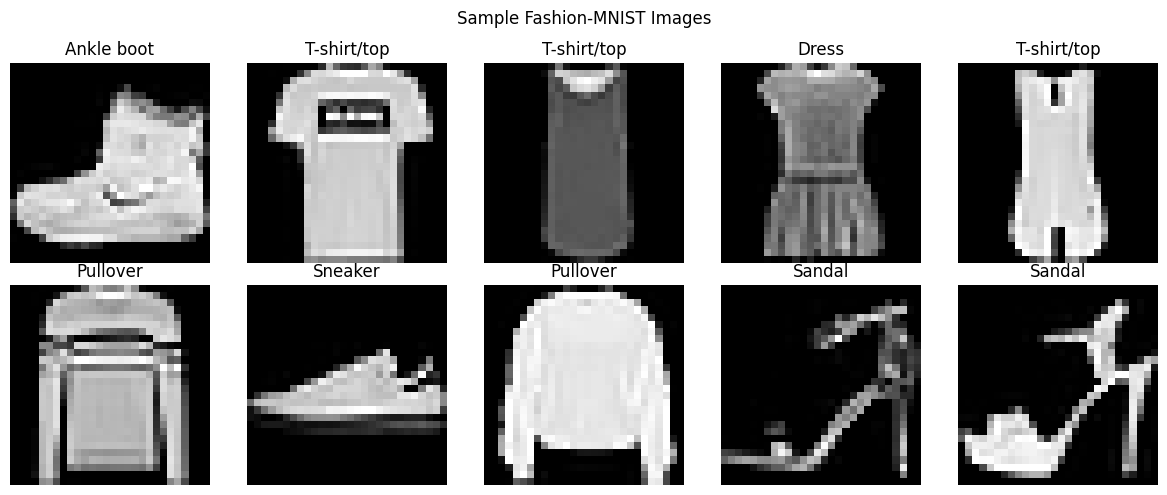

In [15]:
# #step 9 - Display sample Fashion-MNIST images

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(12, 5))

for i in range(10):

    plt.subplot(2, 5, i + 1)

    plt.imshow(X_train_full[i], cmap="gray")

    plt.title(class_names[y_train_full[i]])
    plt.axis("off")

plt.suptitle("Sample Fashion-MNIST Images")
plt.tight_layout()
plt.show()

Fashion-MNIST is a multiclass classification problem.

Unlike XOR, which has two possible outputs, Fashion-MNIST has ten possible classes.

For this experiment:
- Input layer: 784 neurons.
- Hidden layer 1: 128 neurons.
- Hidden layer 2: 64 neurons.
- Output layer: 10 neurons.
- Hidden activation: ReLU.
- Output activation: Softmax.
- Loss: Categorical cross-entropy.
We'll implement everything using NumPy

In [16]:
# #step 10 - Implement multiclass MLP with configurable weight initialization

def softmax(z):

    z = z - np.max(z, axis=1, keepdims=True)

    exp_values = np.exp(z)

    return exp_values / np.sum(exp_values, axis=1, keepdims=True)


class FashionMLP:

    def __init__(self, input_size, hidden1, hidden2,
                 output_size, initialization="he"):

        self.initialization = initialization

        # First layer
        self.W1 = self.init_weights(input_size, hidden1)
        self.b1 = np.zeros((1, hidden1))

        # Second layer
        self.W2 = self.init_weights(hidden1, hidden2)
        self.b2 = np.zeros((1, hidden2))

        # Output layer
        self.W3 = self.init_weights(hidden2, output_size)
        self.b3 = np.zeros((1, output_size))

    def init_weights(self, fan_in, fan_out):

        if self.initialization == "zero":
            return np.zeros((fan_in, fan_out))

        elif self.initialization == "random":
            return np.random.randn(fan_in, fan_out) * 0.1

        elif self.initialization == "xavier":
            return np.random.randn(fan_in, fan_out) * np.sqrt(
                1 / fan_in
            )

        elif self.initialization == "he":
            return np.random.randn(fan_in, fan_out) * np.sqrt(
                2 / fan_in
            )

        else:
            raise ValueError("Unknown initialization method")

    def forward(self, X):

        self.z1 = X @ self.W1 + self.b1
        self.a1 = relu_activation(self.z1)

        self.z2 = self.a1 @ self.W2 + self.b2
        self.a2 = relu_activation(self.z2)

        self.z3 = self.a2 @ self.W3 + self.b3
        self.a3 = softmax(self.z3)

        return self.a3

    def backward(self, X, y, learning_rate):

        m = X.shape[0]

        # Output layer gradient
        dz3 = (self.a3 - y) / m

        dW3 = self.a2.T @ dz3
        db3 = np.sum(dz3, axis=0, keepdims=True)

        # Hidden layer 2 gradient
        dz2 = (dz3 @ self.W3.T) * relu_derivative(self.z2)

        dW2 = self.a1.T @ dz2
        db2 = np.sum(dz2, axis=0, keepdims=True)

        # Hidden layer 1 gradient
        dz1 = (dz2 @ self.W2.T) * relu_derivative(self.z1)

        dW1 = X.T @ dz1
        db1 = np.sum(dz1, axis=0, keepdims=True)

        # Update weights
        self.W3 -= learning_rate * dW3
        self.b3 -= learning_rate * db3

        self.W2 -= learning_rate * dW2
        self.b2 -= learning_rate * db2

        self.W1 -= learning_rate * dW1
        self.b1 -= learning_rate * db1

    def predict(self, X):

        probabilities = self.forward(X)

        return np.argmax(probabilities, axis=1)


print("Fashion-MNIST MLP implemented successfully!")

Fashion-MNIST MLP implemented successfully!


In [17]:
# #step 10 - Train Fashion-MNIST MLP using mini-batch gradient descent

def train_model(model, X_train, y_train, X_test, y_test,
                epochs=10, batch_size=128, learning_rate=0.01):

    num_classes = 10

    # One-hot encode labels
    y_train_onehot = np.eye(num_classes)[y_train]

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "test_accuracy": []
    }

    for epoch in range(epochs):

        # Shuffle training data
        indices = np.random.permutation(len(X_train))

        X_shuffled = X_train[indices]
        y_shuffled = y_train_onehot[indices]

        for start in range(0, len(X_train), batch_size):

            end = start + batch_size

            X_batch = X_shuffled[start:end]
            y_batch = y_shuffled[start:end]

            predictions = model.forward(X_batch)

            model.backward(
                X_batch,
                y_batch,
                learning_rate
            )

        # Evaluate after each epoch
        train_probabilities = model.forward(X_train)

        train_loss = -np.mean(
            np.log(
                np.clip(
                    train_probabilities[
                        np.arange(len(y_train)), y_train
                    ],
                    1e-12,
                    1.0
                )
            )
        )

        train_predictions = np.argmax(train_probabilities, axis=1)
        test_predictions = model.predict(X_test)

        train_accuracy = np.mean(train_predictions == y_train)
        test_accuracy = np.mean(test_predictions == y_test)

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["test_accuracy"].append(test_accuracy)

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Loss: {train_loss:.4f} | "
            f"Train Accuracy: {train_accuracy * 100:.2f}% | "
            f"Test Accuracy: {test_accuracy * 100:.2f}%"
        )

    return history


print("Training function ready!")

Training function ready!


In [18]:
# #step 10 - Train MLP on Fashion-MNIST using He initialization

np.random.seed(42)

fashion_model = FashionMLP(
    input_size=784,
    hidden1=128,
    hidden2=64,
    output_size=10,
    initialization="he"
)

fashion_history = train_model(
    fashion_model,
    X_train_fashion,
    y_train_fashion,
    X_test_fashion,
    y_test_fashion,
    epochs=10,
    batch_size=128,
    learning_rate=0.01
)

Epoch 1/10 | Loss: 1.4184 | Train Accuracy: 62.49% | Test Accuracy: 59.90%
Epoch 2/10 | Loss: 1.0603 | Train Accuracy: 68.29% | Test Accuracy: 66.85%
Epoch 3/10 | Loss: 0.9089 | Train Accuracy: 71.56% | Test Accuracy: 70.00%
Epoch 4/10 | Loss: 0.8266 | Train Accuracy: 72.92% | Test Accuracy: 71.40%
Epoch 5/10 | Loss: 0.7762 | Train Accuracy: 75.62% | Test Accuracy: 74.00%
Epoch 6/10 | Loss: 0.7174 | Train Accuracy: 76.79% | Test Accuracy: 75.50%
Epoch 7/10 | Loss: 0.6926 | Train Accuracy: 77.11% | Test Accuracy: 75.75%
Epoch 8/10 | Loss: 0.6789 | Train Accuracy: 76.80% | Test Accuracy: 74.95%
Epoch 9/10 | Loss: 0.6334 | Train Accuracy: 79.19% | Test Accuracy: 78.05%
Epoch 10/10 | Loss: 0.6258 | Train Accuracy: 78.97% | Test Accuracy: 77.75%


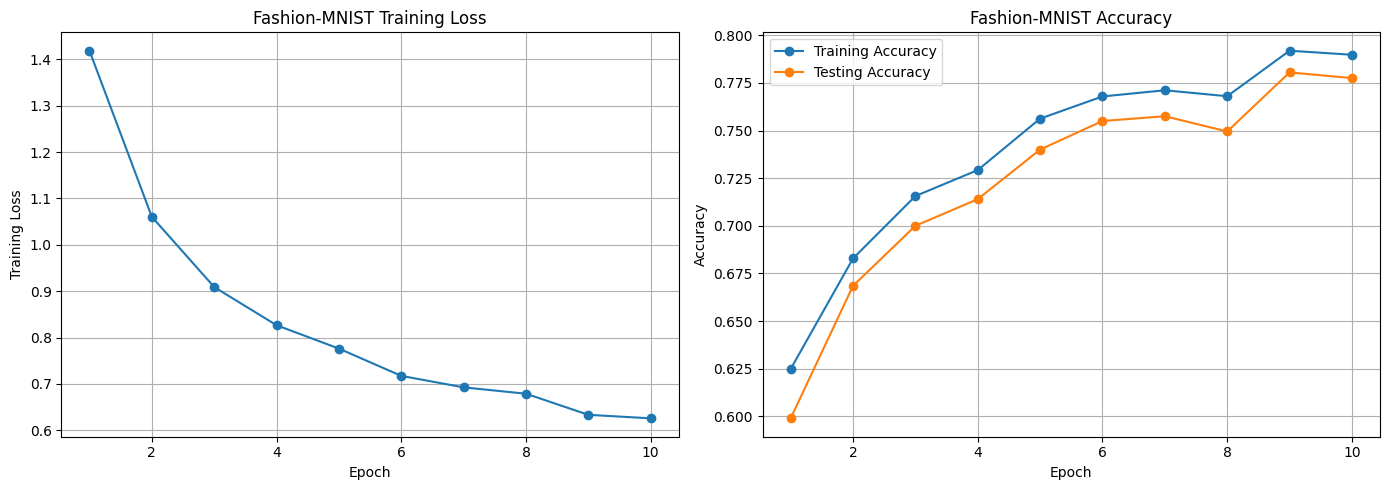

In [19]:
# #step 11 - Plot Fashion-MNIST training loss and accuracy

epochs_range = range(1, len(fashion_history["train_loss"]) + 1)

plt.figure(figsize=(14, 5))

# Loss plot
plt.subplot(1, 2, 1)

plt.plot(
    epochs_range,
    fashion_history["train_loss"],
    marker="o"
)

plt.xlabel("Epoch")
plt.ylabel("Training Loss")
plt.title("Fashion-MNIST Training Loss")
plt.grid(True)

# Accuracy plot
plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    fashion_history["train_accuracy"],
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    epochs_range,
    fashion_history["test_accuracy"],
    marker="o",
    label="Testing Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Fashion-MNIST Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [20]:
# #step 12 - Compare initialization methods on Fashion-MNIST

initialization_methods = ["zero", "random", "xavier", "he"]

initialization_performance = []

for method in initialization_methods:

    print("\nTraining with", method, "initialization")
    print("-" * 45)

    np.random.seed(42)

    model = FashionMLP(
        input_size=784,
        hidden1=128,
        hidden2=64,
        output_size=10,
        initialization=method
    )

    history = train_model(
        model,
        X_train_fashion,
        y_train_fashion,
        X_test_fashion,
        y_test_fashion,
        epochs=6,
        batch_size=128,
        learning_rate=0.01
    )

    initialization_performance.append({
        "Initialization": method,
        "Final Training Loss": history["train_loss"][-1],
        "Training Accuracy (%)": history["train_accuracy"][-1] * 100,
        "Testing Accuracy (%)": history["test_accuracy"][-1] * 100
    })


initialization_comparison = pd.DataFrame(initialization_performance)

print("\nInitialization Performance Comparison")
print(initialization_comparison.round(4).to_string(index=False))


Training with zero initialization
---------------------------------------------
Epoch 1/6 | Loss: 2.3025 | Train Accuracy: 10.75% | Test Accuracy: 10.15%
Epoch 2/6 | Loss: 2.3024 | Train Accuracy: 10.75% | Test Accuracy: 10.15%
Epoch 3/6 | Loss: 2.3024 | Train Accuracy: 10.75% | Test Accuracy: 10.15%
Epoch 4/6 | Loss: 2.3023 | Train Accuracy: 10.75% | Test Accuracy: 10.15%
Epoch 5/6 | Loss: 2.3023 | Train Accuracy: 10.75% | Test Accuracy: 10.15%
Epoch 6/6 | Loss: 2.3022 | Train Accuracy: 10.75% | Test Accuracy: 10.15%

Training with random initialization
---------------------------------------------
Epoch 1/6 | Loss: 1.7138 | Train Accuracy: 53.99% | Test Accuracy: 52.25%
Epoch 2/6 | Loss: 1.3149 | Train Accuracy: 63.35% | Test Accuracy: 62.00%
Epoch 3/6 | Loss: 1.0991 | Train Accuracy: 66.53% | Test Accuracy: 64.55%
Epoch 4/6 | Loss: 0.9713 | Train Accuracy: 68.39% | Test Accuracy: 65.65%
Epoch 5/6 | Loss: 0.8987 | Train Accuracy: 71.50% | Test Accuracy: 68.35%
Epoch 6/6 | Loss: 0.83

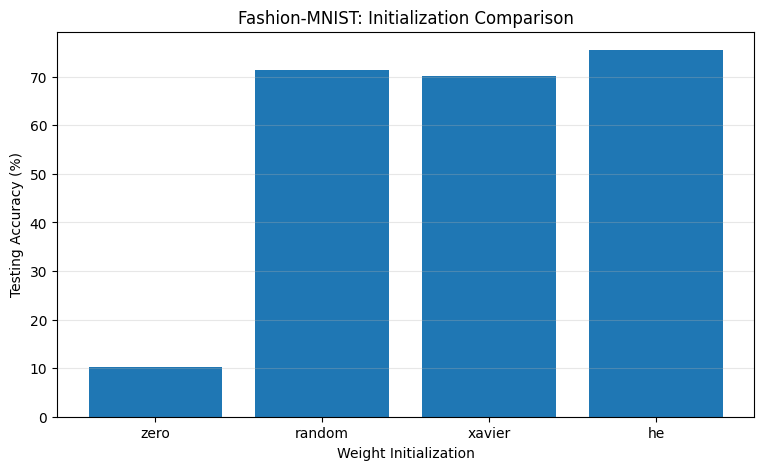

In [21]:
# #step 12 - Visualize initialization performance comparison

plt.figure(figsize=(9, 5))

plt.bar(
    initialization_comparison["Initialization"],
    initialization_comparison["Testing Accuracy (%)"]
)

plt.xlabel("Weight Initialization")
plt.ylabel("Testing Accuracy (%)")
plt.title("Fashion-MNIST: Initialization Comparison")
plt.grid(axis="y", alpha=0.3)

plt.show()

In [22]:
# #step 13 - Evaluate predictions and display classification report

from sklearn.metrics import classification_report, confusion_matrix

final_predictions = fashion_model.predict(X_test_fashion)

print("Classification Report:\n")

print(
    classification_report(
        y_test_fashion,
        final_predictions,
        target_names=class_names,
        zero_division=0
    )
)

print("Overall Test Accuracy:",
      np.mean(final_predictions == y_test_fashion) * 100, "%")

Classification Report:

              precision    recall  f1-score   support

 T-shirt/top       0.76      0.80      0.78       200
     Trouser       0.95      0.92      0.94       203
    Pullover       0.81      0.51      0.62       214
       Dress       0.78      0.84      0.81       190
        Coat       0.59      0.84      0.70       219
      Sandal       0.92      0.78      0.85       195
       Shirt       0.44      0.38      0.41       197
     Sneaker       0.82      0.89      0.85       200
         Bag       0.93      0.91      0.92       194
  Ankle boot       0.85      0.93      0.89       188

    accuracy                           0.78      2000
   macro avg       0.79      0.78      0.78      2000
weighted avg       0.78      0.78      0.77      2000

Overall Test Accuracy: 77.75 %


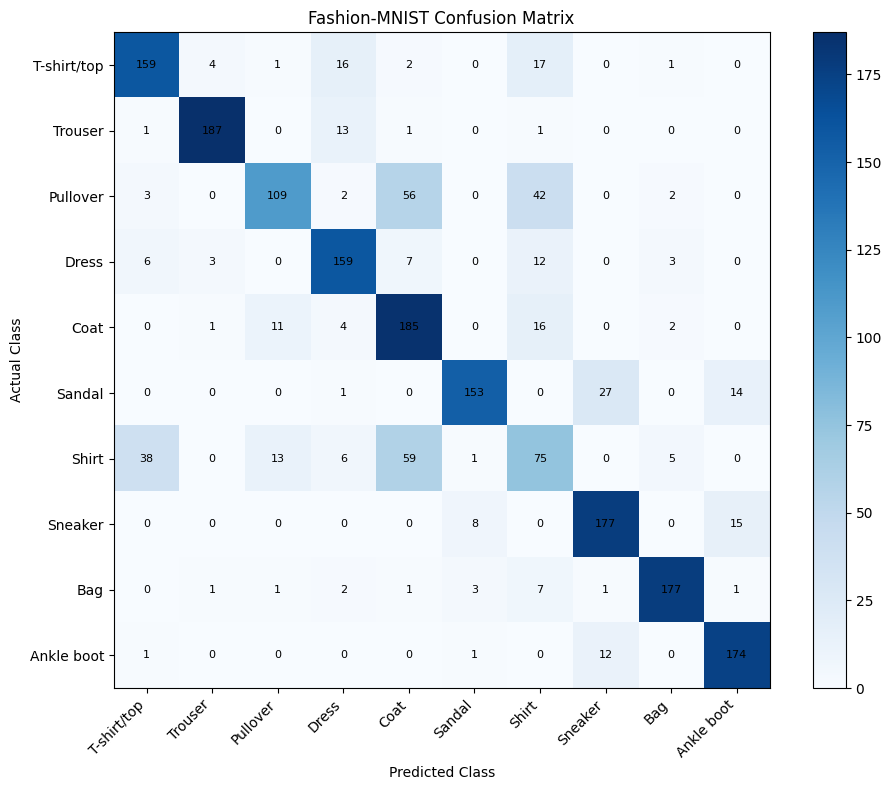

In [23]:
# #step 13 - Visualize confusion matrix

cm = confusion_matrix(
    y_test_fashion,
    final_predictions
)

plt.figure(figsize=(10, 8))

plt.imshow(cm, cmap="Blues")
plt.colorbar()

plt.xticks(range(10), class_names, rotation=45, ha="right")
plt.yticks(range(10), class_names)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Fashion-MNIST Confusion Matrix")

for i in range(10):
    for j in range(10):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=8)

plt.tight_layout()
plt.show()

## Conclusion – Multilayer Perceptron with Backpropagation

1. A single-layer perceptron successfully learns linearly separable problems such as AND but fails to correctly classify XOR because XOR is not linearly separable.

2. By introducing a hidden layer, the Multilayer Perceptron (MLP) learns non-linear relationships and successfully solves the XOR problem using forward propagation and backpropagation.

3. Numerical gradient checking was performed by comparing analytical gradients with numerical gradients. Their close agreement verifies the correctness of the implemented backpropagation algorithm.

4. Four weight initialization methods were compared: Zero, Random, Xavier and He initialization. Zero initialization performed poorly, achieving only 10.15% testing accuracy because identical initial weights prevent neurons from learning different features.

5. Random, Xavier and He initialization performed considerably better. He initialization achieved the highest testing accuracy of 75.50% after six epochs, making it the best-performing method in this experiment.

6. The MLP was trained on a subset of Fashion-MNIST containing 8,000 training images and evaluated on 2,000 test images. The network used two hidden layers with ReLU activation and a Softmax output layer.

7. The final model achieved an overall testing accuracy of **77.75%**, demonstrating that a NumPy-based MLP can perform multiclass image classification.

8. The classification report showed that Trouser and Bag were classified particularly well, while Shirt had the lowest F1-score of 0.41. This indicates that visually similar clothing categories are more challenging to classify.

9. Training loss, accuracy curves, classification reports and confusion matrices were used to evaluate the model's performance.

**Overall**, this experiment demonstrates the importance of hidden layers, backpropagation, numerical gradient verification and appropriate weight initialization in building and training neural networks for both logical operations and image classification.